# Plot the ARMD Antibiogram with Python

This notebook uses **pandas and Matplotlib** to plot the susceptibility mart as six antibiogram tables: blood, urine, and respiratory cultures, each split into Gram-negative and Gram-positive organisms. The Tableau charts guide the appearance; all organism rows, antibiotic columns, counts, and percentages come from the mart.

**Input:** `data/exports/mart_susceptibility.csv`. Change `MART_RELATIVE_PATH` to use a mart produced by the local Python or R build. Run the notebook from top to bottom in a fresh Python kernel.

**Packages:** pandas and Matplotlib. Install into the selected notebook environment with `%pip install pandas matplotlib` if needed.

Each chart appears in the notebook and is saved as a PNG under `docs/figures/antibiogram/python/`.

## 1. Load the susceptibility mart

The notebook locates the input within the repository, so it can run from the repository root or the notebook's directory.

In [1]:
from pathlib import Path
from math import floor
import textwrap
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display

MART_RELATIVE_PATH = "data/exports/mart_susceptibility.csv"

def find_repository_root(start):
    for path in (start, *start.parents):
        if (path / MART_RELATIVE_PATH).is_file():
            return path
    raise FileNotFoundError(f"Could not find {MART_RELATIVE_PATH}. Run inside the repository and check the input path.")

ROOT = find_repository_root(Path.cwd().resolve())
OUTPUT_DIR = ROOT / "docs/figures/antibiogram/python"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
mart = pd.read_csv(ROOT / MART_RELATIVE_PATH, encoding="utf-8-sig")
plt.rcParams.update({"font.family": "DejaVu Sans"})

## 2. Check the input

Each organism–antibiotic endpoint must be unique within its specimen and Gram group. A single reporting period is required to avoid combining percentages from different populations.

In [2]:
required = {"cohort_id", "gram_stain_group", "organism_name", "antibiotic",
            "eligible_count", "susceptible_pct", "source_version",
            "analysis_window_start", "analysis_window_end_exclusive"}
missing = required - set(mart.columns)
if missing:
    raise ValueError(f"Missing mart columns: {sorted(missing)}")

for column in ["cohort_id", "gram_stain_group", "organism_name", "antibiotic"]:
    if mart[column].isna().any():
        raise ValueError(f"Missing values in {column}")
    mart[column] = mart[column].str.strip()

scope_columns = ["source_version", "analysis_window_start", "analysis_window_end_exclusive"]
scope_rows = mart[scope_columns].fillna("full-release").drop_duplicates()
if len(scope_rows) != 1:
    raise ValueError("Select a single source release and reporting window before plotting.")
scope = scope_rows.iloc[0].to_dict()

population_key = ["cohort_id", "gram_stain_group", "organism_name"]
if mart.duplicated(population_key + ["antibiotic"]).any():
    raise ValueError("Duplicate organism–antibiotic endpoints; preaggregated percentages cannot be summed or averaged.")
mart["eligible_count"] = pd.to_numeric(mart["eligible_count"], errors="raise")
mart["susceptible_pct"] = pd.to_numeric(mart["susceptible_pct"], errors="raise")
if mart.eligible_count.isna().any() or (mart.eligible_count < 0).any() or (mart.eligible_count % 1 != 0).any():
    raise ValueError("Eligible counts must be nonnegative whole numbers.")
if mart.groupby(population_key).eligible_count.nunique().gt(1).any():
    raise ValueError("Eligible counts differ across antibiotics within a population.")
if not mart.susceptible_pct.dropna().between(0, 100).all():
    raise ValueError("Susceptibility percentages must use the 0–100 scale.")
print(f"Loaded {len(mart):,} organism–antibiotic endpoints.")

Loaded 396 organism–antibiotic endpoints.


## 3. Arrange organisms and antibiotics

Rows and columns are derived from the selected data and sorted alphabetically. `%S` uses the mart's `susceptible_pct`; `N` uses `eligible_count` once per organism population. Missing cells remain blank and true zero susceptibility displays as `0%`.

All available mart endpoints are included, including small populations marked `insufficient_data`. The notebook does not apply a minimum-count filter.

In [3]:
def prepare_panel(cohort, gram):
    selected = mart.loc[mart.cohort_id.eq(cohort) & mart.gram_stain_group.eq(gram)]
    if selected.empty:
        raise ValueError(f"No data for {cohort}, {gram}.")
    organisms = sorted(selected.organism_name.unique())
    antibiotics = sorted(selected.antibiotic.unique())
    values = selected.pivot(index="organism_name", columns="antibiotic", values="susceptible_pct")
    values = values.reindex(index=organisms, columns=antibiotics)
    counts = selected.groupby("organism_name").eligible_count.first().reindex(organisms)
    labels = values.apply(lambda column: column.map(
        lambda value: "" if pd.isna(value) else f"{floor(value + 0.5)}%"))
    return {"values": values, "labels": labels, "counts": counts}

## 4. Draw the antibiogram table

Matplotlib rectangles and text create the blue headers, rotated antibiotic labels, alternate row shading, and separate population-count column.

In [4]:
def plot_antibiogram(cohort, gram):
    table = prepare_panel(cohort, gram)
    title = f"{cohort.title()} Culture {gram.replace('_', '-').title()} Organisms"
    labels, counts = table["labels"], table["counts"]
    row_height, organism_width, count_width, drug_width = 0.43, 4.25, 0.80, 0.61
    header_height, band_height = 2.25, 0.28
    nrows, ncols = labels.shape
    body_height = nrows * row_height
    start_drugs = organism_width + count_width
    width = start_drugs + ncols * drug_width
    top = body_height + header_height + band_height
    height = top + 1.65
    fig, ax = plt.subplots(figsize=(width + 0.3, height))
    fig.subplots_adjust(left=0.01, right=0.99, bottom=0.01, top=0.99)
    ax.set(xlim=(-0.08, width + 0.08), ylim=(-0.90, top + 0.75))
    ax.set_aspect("equal")
    ax.axis("off")

    def cell(x, y, w, h, fill):
        ax.add_patch(Rectangle((x, y), w, h, facecolor=fill, edgecolor="#333333", linewidth=0.45))

    for i, organism in enumerate(labels.index):
        y = body_height - (i + 1) * row_height
        fill = "#ffffff" if i % 2 == 0 else "#e7e7e8"
        cell(0, y, organism_width, row_height, fill)
        cell(organism_width, y, count_width, row_height, fill)
        ax.text(0.08, y + row_height/2, textwrap.fill(organism, 48), va="center", fontsize=9)
        ax.text(organism_width + count_width/2, y + row_height/2, str(int(counts.loc[organism])), ha="center", va="center", fontsize=9)
        for j, antibiotic in enumerate(labels.columns):
            x = start_drugs + j * drug_width
            cell(x, y, drug_width, row_height, fill)
            ax.text(x + drug_width/2, y + row_height/2, labels.loc[organism, antibiotic], ha="center", va="center", fontsize=9)

    for x, w, label in [(0, organism_width, "Organism name"), (organism_width, count_width, "Eligible\nfirst\ncultures\n(N)")]:
        cell(x, body_height, w, header_height, "#ffffff")
        ax.text(x + (0.08 if x == 0 else w/2), body_height + 0.12,
                label, ha="left" if x == 0 else "center", va="bottom", fontsize=9)
    for j, antibiotic in enumerate(labels.columns):
        x = start_drugs + j * drug_width
        cell(x, body_height, drug_width, header_height, "#87c4eb")
        ax.text(x + drug_width/2, body_height + 0.12, antibiotic,
                rotation=90, va="bottom", ha="center", fontsize=8.5, color="#173747")
    cell(start_drugs, body_height + header_height, ncols * drug_width, band_height, "#019eda")
    ax.text(start_drugs + ncols * drug_width/2, top - band_height/2, "% Susceptible", ha="center", va="center", fontsize=10, color="white", weight="bold")
    ax.text(0, top + 0.52, title, fontsize=16, weight="bold", va="center")
    ax.text(0, top + 0.22,
            f"ARMD release {scope['source_version']} | Shifted-date window: {scope['analysis_window_start']} to {scope['analysis_window_end_exclusive']} (exclusive)",
            fontsize=8, color="#555555", va="center")
    ax.text(0, -0.25, "All available mart endpoints are shown, including results with small denominators.",
            fontsize=8, color="#555555", va="center")
    ax.text(0, -0.49, "N = eligible first cultures in each population; %S uses the drug-specific S/I/R denominator. Blank is not 0%.", fontsize=8, color="#555555", va="center")
    ax.text(0, -0.73, "Phenotype populations overlap and are not additive. Retrospective portfolio demonstration.", fontsize=8, color="#555555", va="center")
    return fig

## Blood culture gram-negative organisms

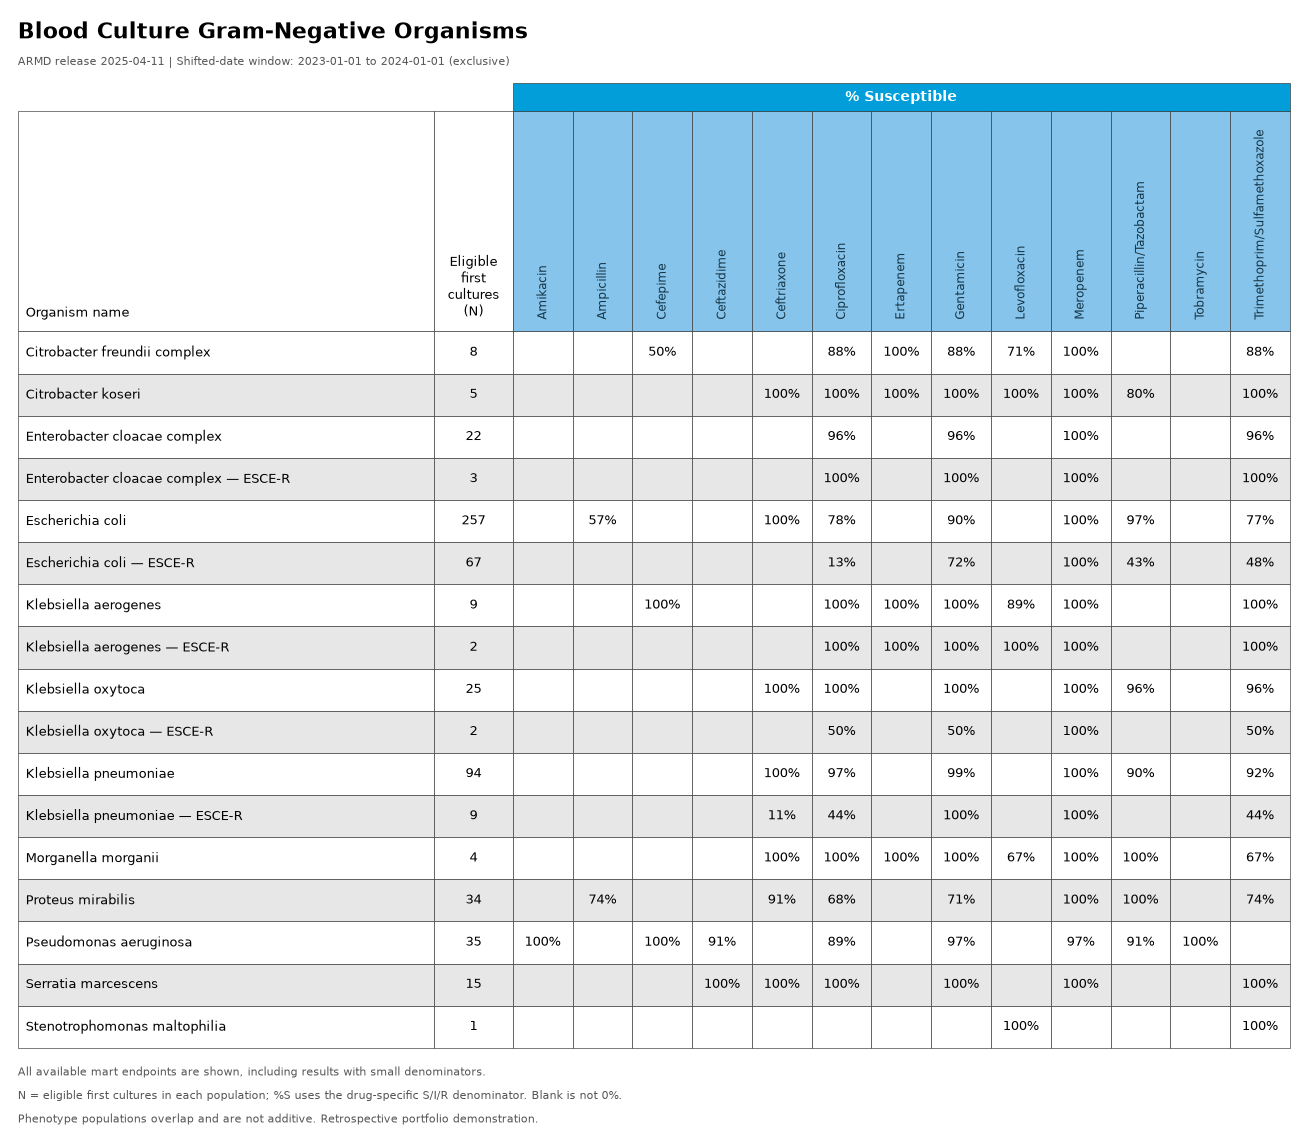

In [5]:
fig = plot_antibiogram("blood", "gram_negative")
fig.savefig(OUTPUT_DIR / "blood_gram_negative.png", dpi=180, facecolor="white")
display(fig)
plt.close(fig)

## Urine culture gram-negative organisms

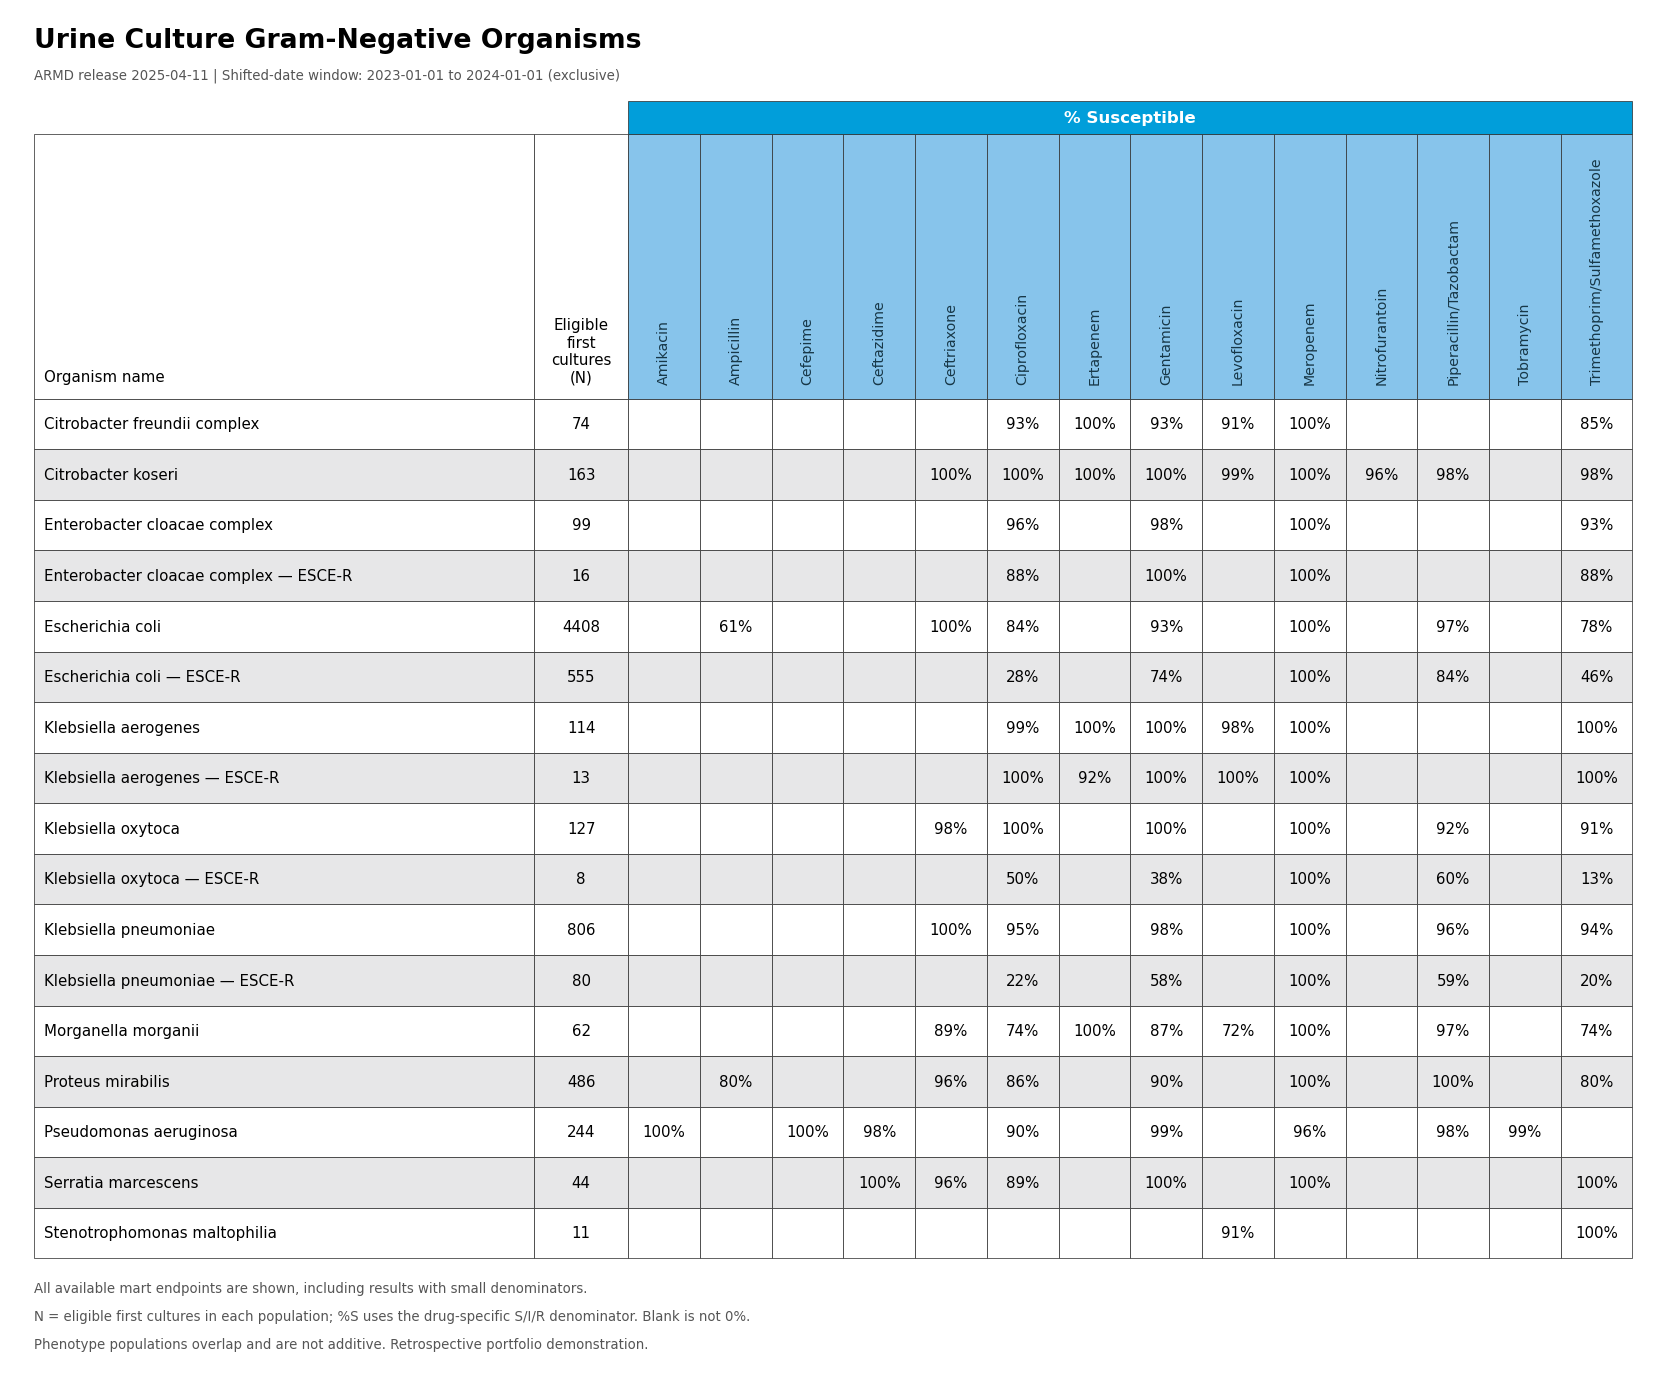

In [6]:
fig = plot_antibiogram("urine", "gram_negative")
fig.savefig(OUTPUT_DIR / "urine_gram_negative.png", dpi=180, facecolor="white")
display(fig)
plt.close(fig)

## Respiratory culture gram-negative organisms

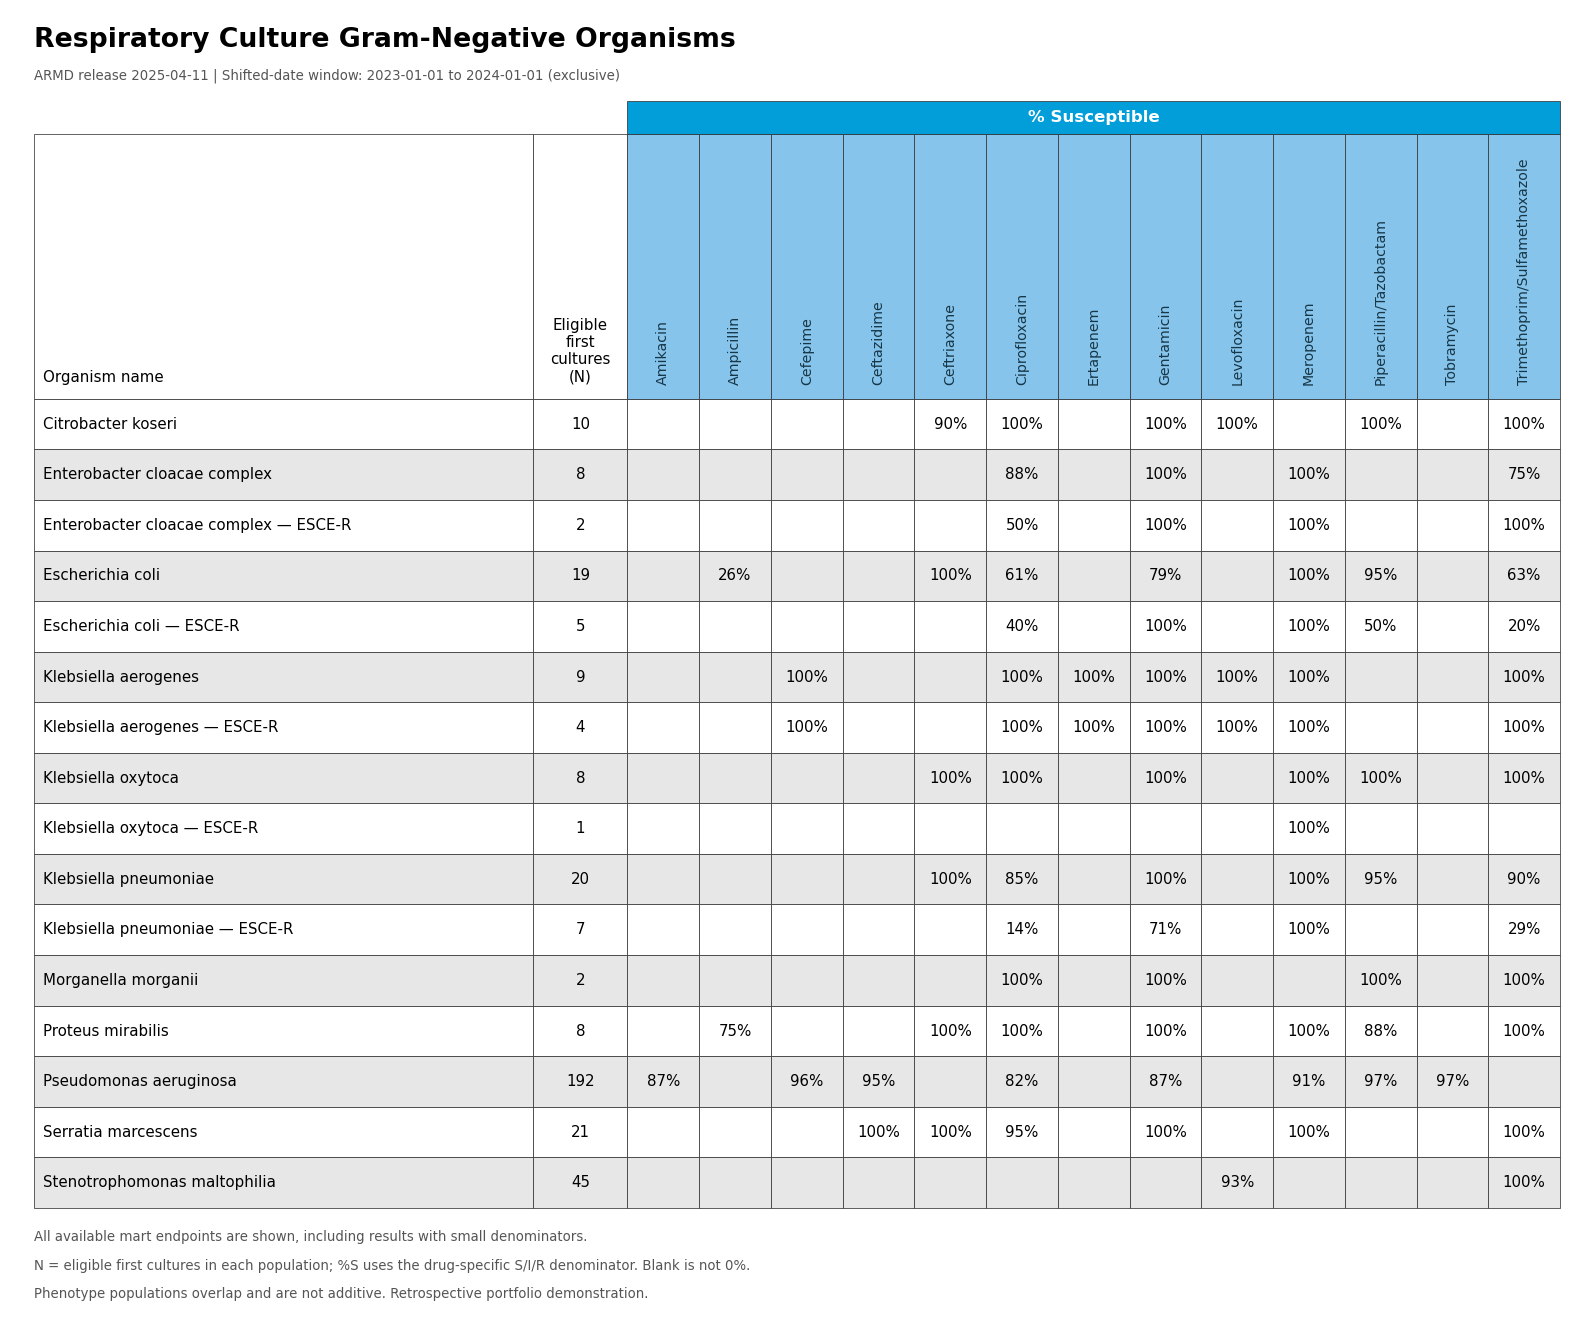

In [7]:
fig = plot_antibiogram("respiratory", "gram_negative")
fig.savefig(OUTPUT_DIR / "respiratory_gram_negative.png", dpi=180, facecolor="white")
display(fig)
plt.close(fig)

## Blood culture gram-positive organisms

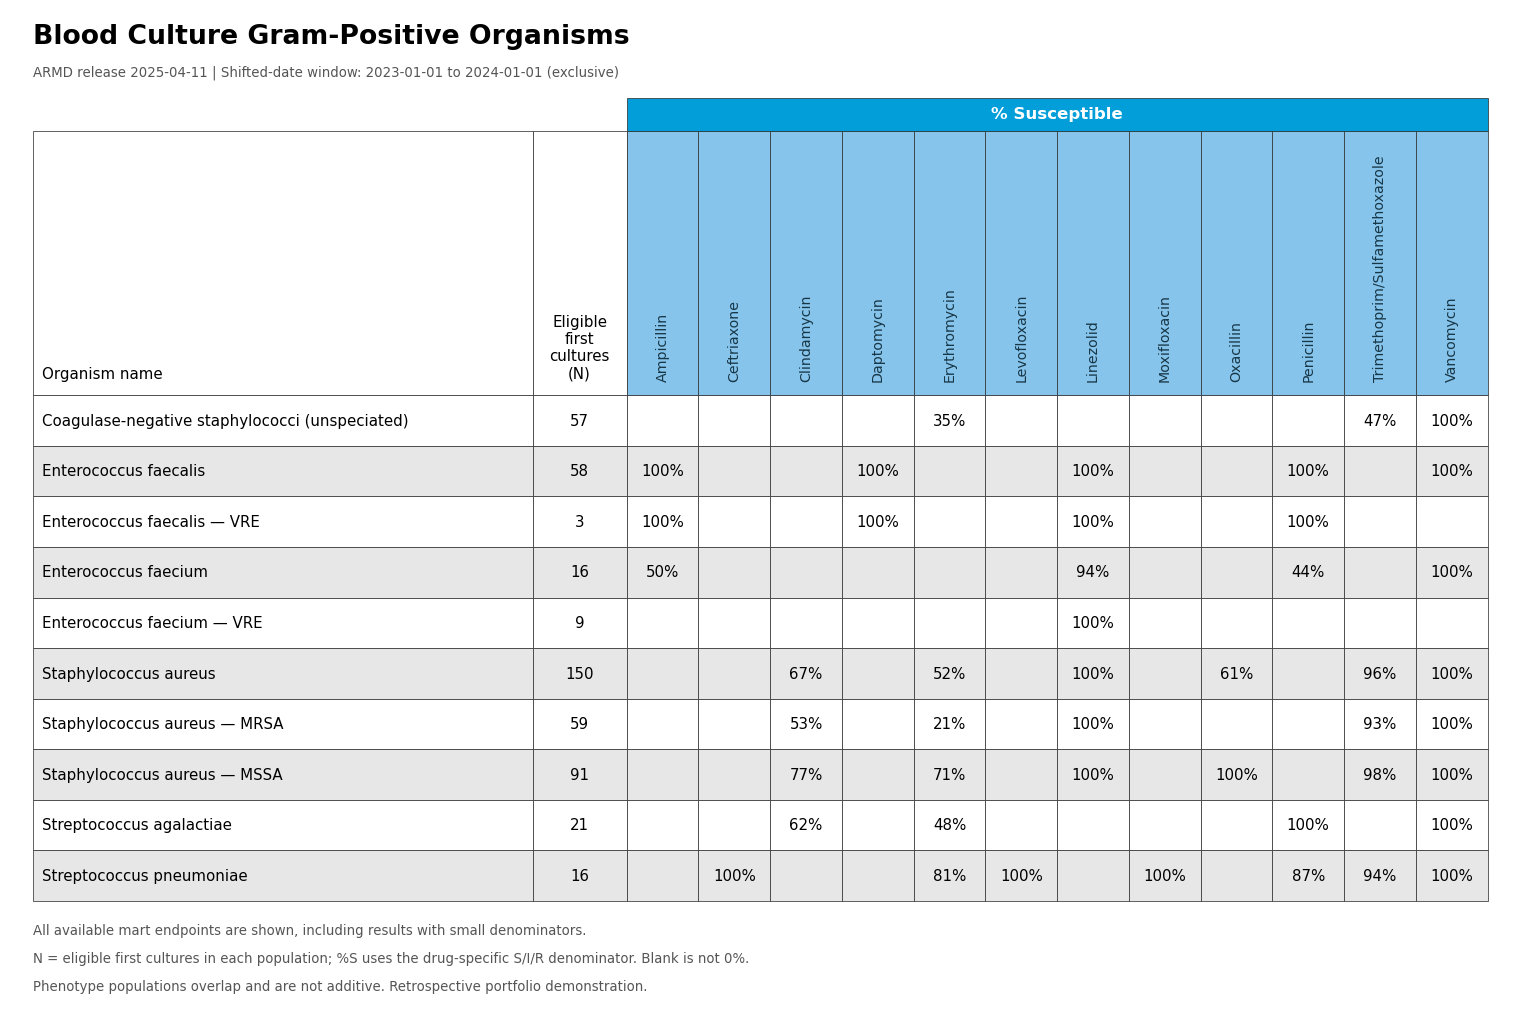

In [8]:
fig = plot_antibiogram("blood", "gram_positive")
fig.savefig(OUTPUT_DIR / "blood_gram_positive.png", dpi=180, facecolor="white")
display(fig)
plt.close(fig)

## Urine culture gram-positive organisms

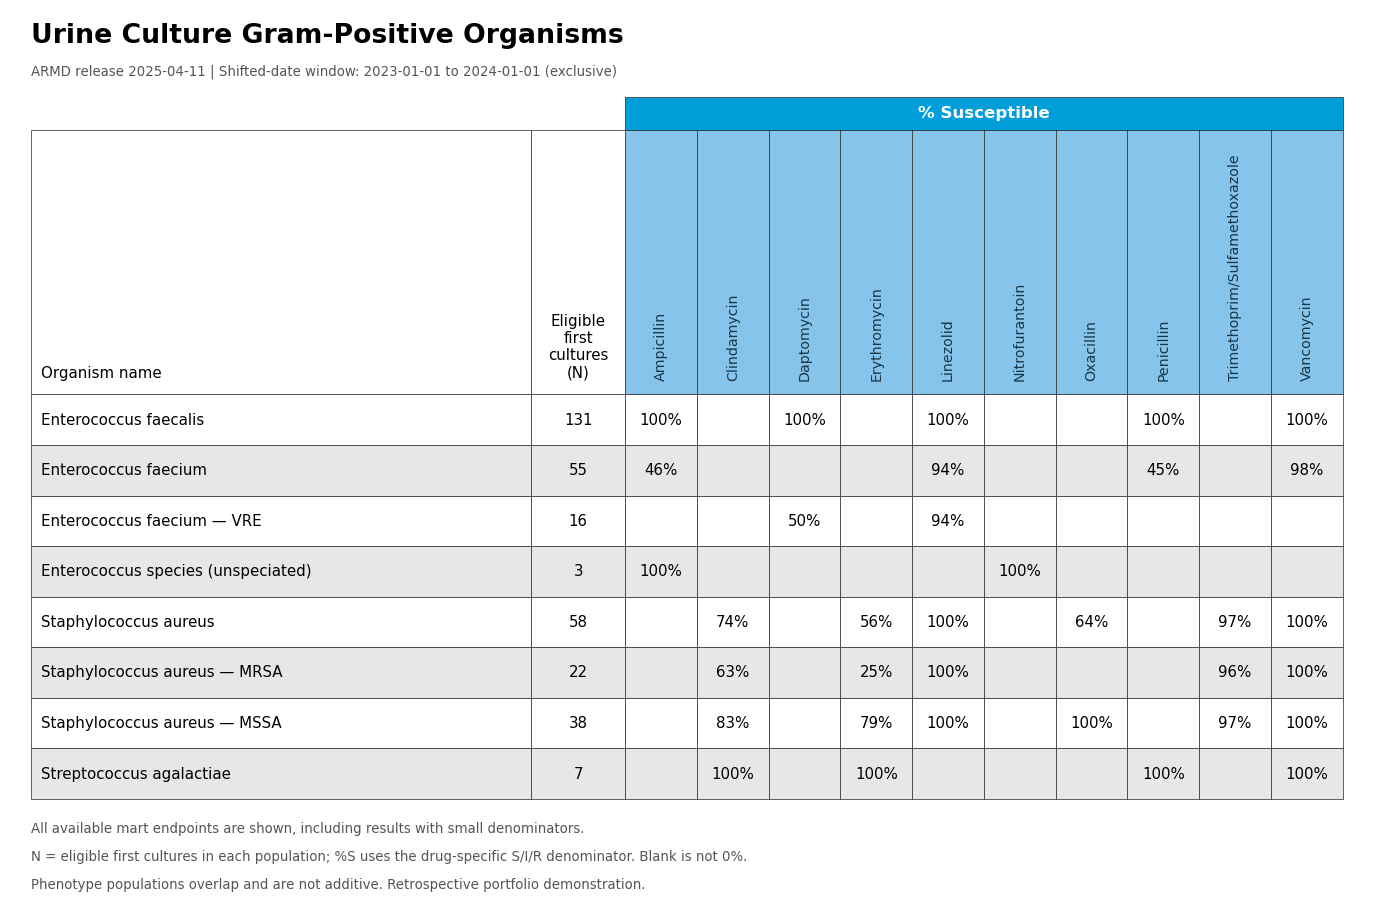

In [9]:
fig = plot_antibiogram("urine", "gram_positive")
fig.savefig(OUTPUT_DIR / "urine_gram_positive.png", dpi=180, facecolor="white")
display(fig)
plt.close(fig)

## Respiratory culture gram-positive organisms

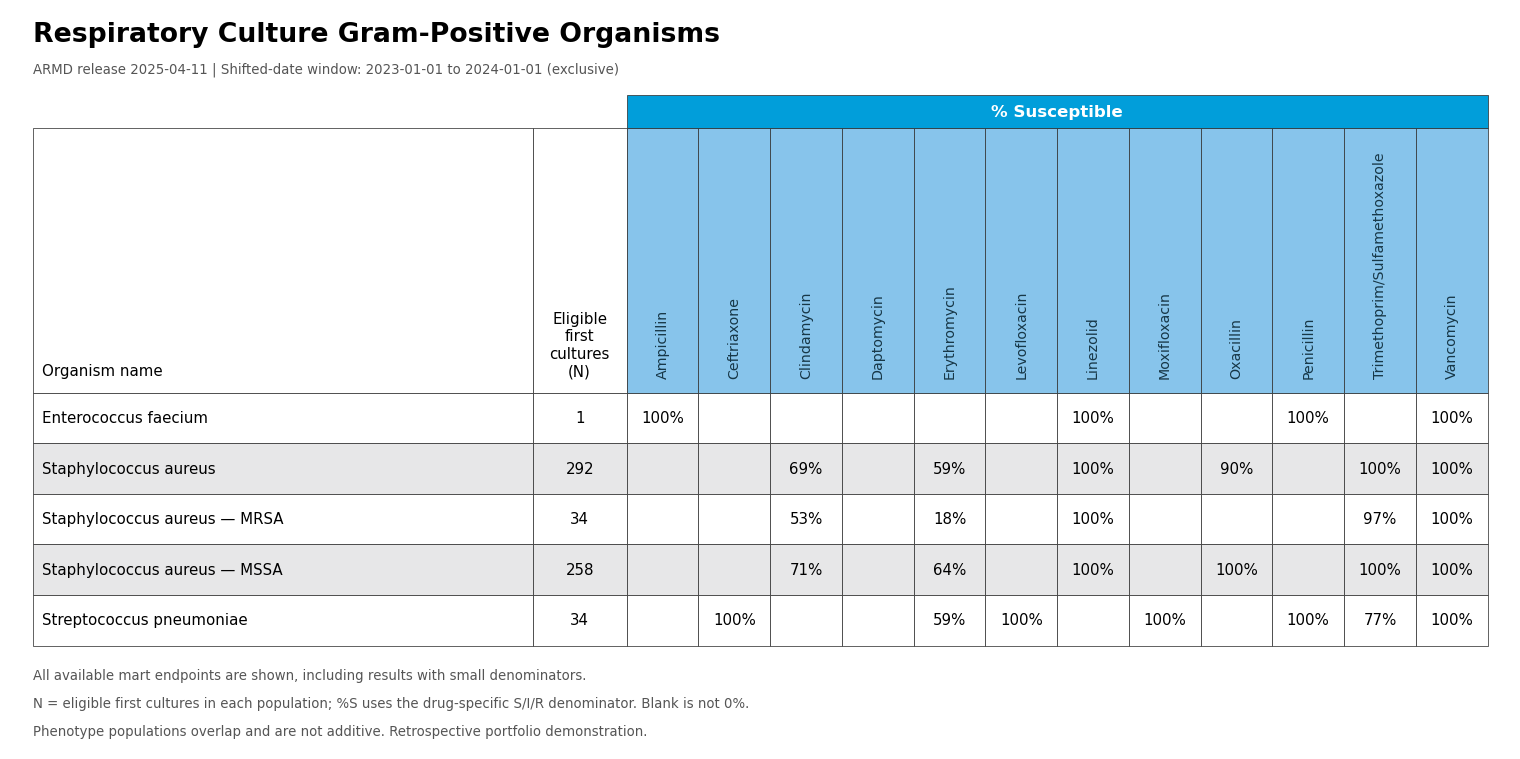

In [10]:
fig = plot_antibiogram("respiratory", "gram_positive")
fig.savefig(OUTPUT_DIR / "respiratory_gram_positive.png", dpi=180, facecolor="white")
display(fig)
plt.close(fig)